# Personal Fitness Analytics
**William J. Warkentin | GSBA 594**

Research question: How have my training consistency and cycling performance changed, and can pre-ride information predict average watts?

Run all cells in order. See README for setup. This notebook uses the accompanying commented Python script.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from analyze_peloton import load_data, descriptive, make_features, model_analysis

CSV_PATH = Path("workouts.csv")
OUT = Path("notebook_results")
OUT.mkdir(exist_ok=True)


## 1. Inspect and clean
Handle mixed timestamp suffixes and resistance percentages. Keep unavailable metrics missing rather than interpreting them as zero.

In [2]:
df, audit, missing = load_data(CSV_PATH)
print(audit)
display(df.head())
display(missing.to_frame())
display(df.groupby("discipline").minutes.agg(["count", "sum"]))

{'input_rows': 1688, 'exact_duplicate_rows': 0, 'invalid_dates': 0, 'invalid_durations': 0, 'timestamp_policy': 'Local wall-clock time; timezone suffix removed, no UTC conversion.', 'retained_rows': 1688}


,timestamp,Live/On-Demand,instructor,minutes,discipline,type,title,Class Timestamp,output_kj,watts,resistance,cadence,Avg. Speed (mph),miles,calories,heart_rate,Avg. Incline,Avg. Pace (min/mi),date
0,2021-03-11 16:49 (-08),On Demand,Tunde Oyeneyin,20.0,Cycling,Beginner,20 min Beginner Ride,2020-10-08 13:00 (-08),118.0,98.0,40.0,75.0,15.99,5.33,158.0,NaN,NaN,NaN,2021-03-11 16:49:00
1,2021-03-11 17:13 (-08),On Demand,Unknown,15.0,Cycling,Scenic Ride,15 min Wellington Scenic Ride,NaN,78.0,86.0,36.0,80.0,15.22,3.81,166.0,91.43,NaN,NaN,2021-03-11 17:13:00
2,2021-03-12 06:17 (-08),On Demand,Emma Lovewell,20.0,Cycling,Low Impact,20 min Low Impact Ride,2020-08-03 08:07 (-08),123.0,102.0,37.0,85.0,16.16,5.39,240.0,128.75,NaN,NaN,2021-03-12 06:17:00
3,2021-03-12 16:54 (-08),On Demand,Leanne Hainsby-Alldis,30.0,Cycling,Music,30 min The Beatles Ride Vol. 1,2020-12-25 01:00 (-08),216.0,120.0,40.0,84.0,17.30,8.65,331.0,163.24,NaN,NaN,2021-03-12 16:54:00
4,2021-03-14 16:17 (-07),On Demand,Jenn Sherman,30.0,Cycling,Music,30 min Classic Rock Ride,2020-10-13 08:22 (-07),203.0,113.0,42.0,77.0,16.83,8.42,422.0,142.06,NaN,NaN,2021-03-14 16:17:00


,missing_fraction
Workout Timestamp,0.000000
Live/On-Demand,0.126185
Instructor Name,0.133294
Length (minutes),0.000000
Fitness Discipline,0.000000
Type,0.126185
Title,0.000000
Class Timestamp,0.134479
Total Output,0.454384
Avg. Watts,0.609597


,count,sum
discipline,,
Cardio,5,80.0
Cycling,659,15500.0
Meditation,363,2728.0
Row Bootcamp,1,10.0
Rowing,41,400.0
Strength,166,1660.0
Stretching,232,1313.0
Walking,220,5365.0
Yoga,1,5.0


## 2. Explore consistency and comparable rides
All activities contribute to weekly logged minutes. Performance analysis uses main cycling rides of at least 15 minutes, excluding warm-ups/cool-downs. Matching duration and type improves comparability but does not control for effort or difficulty.

Main rides: 434


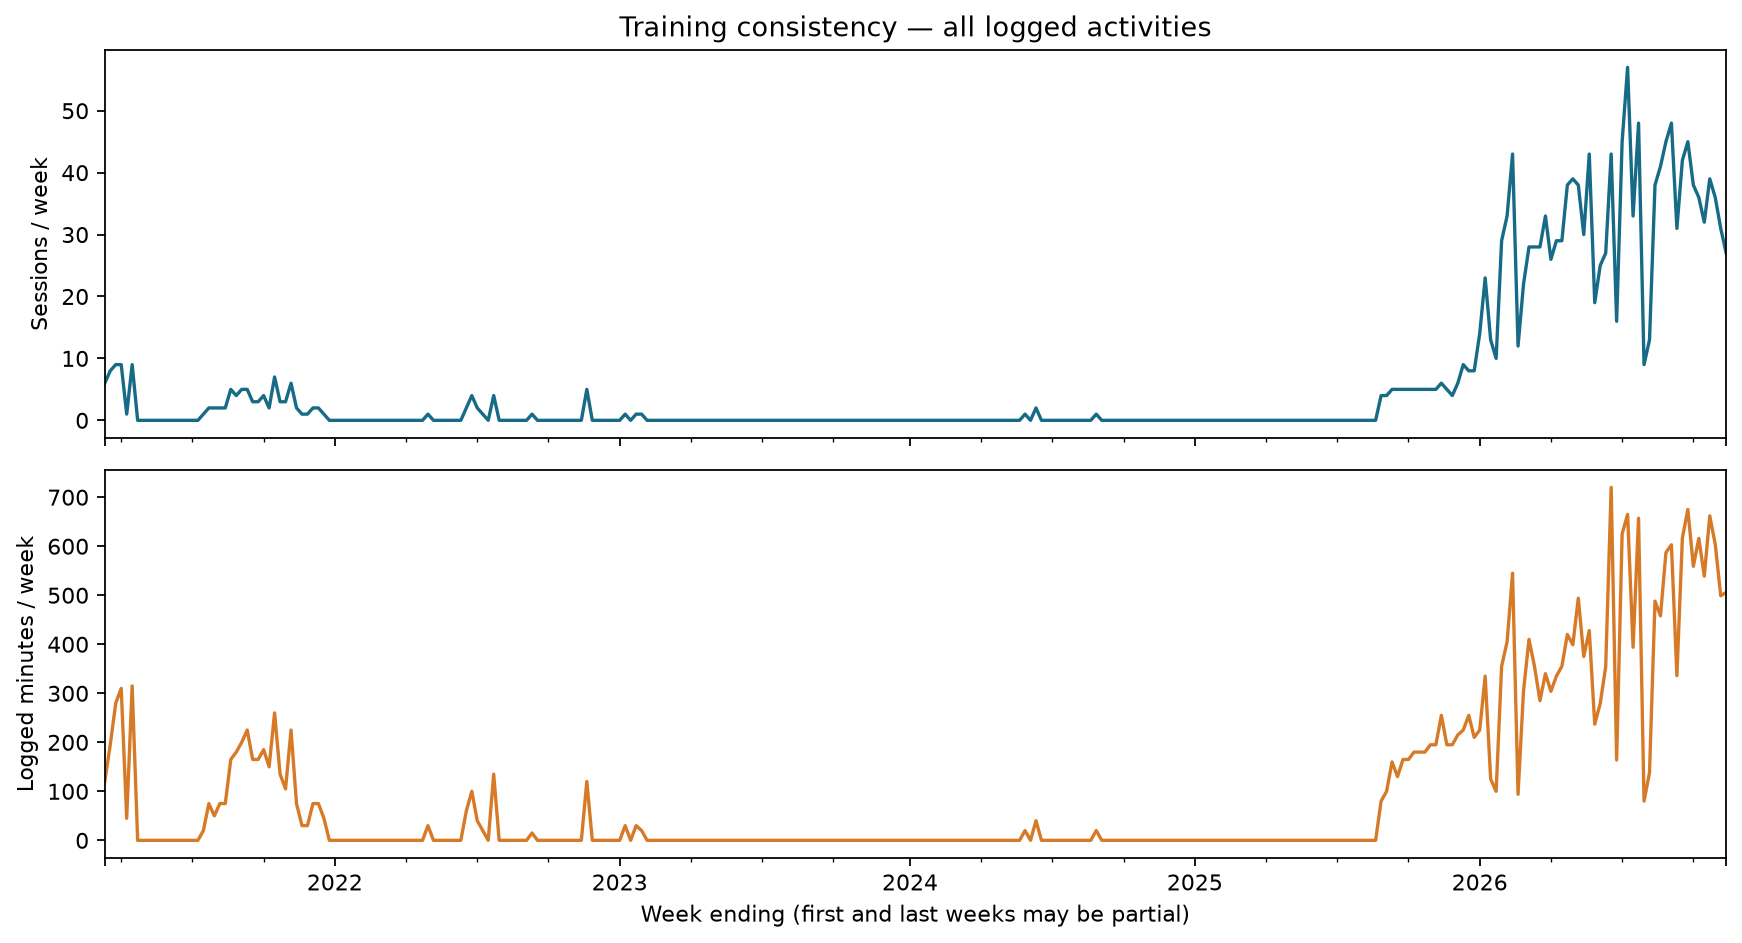

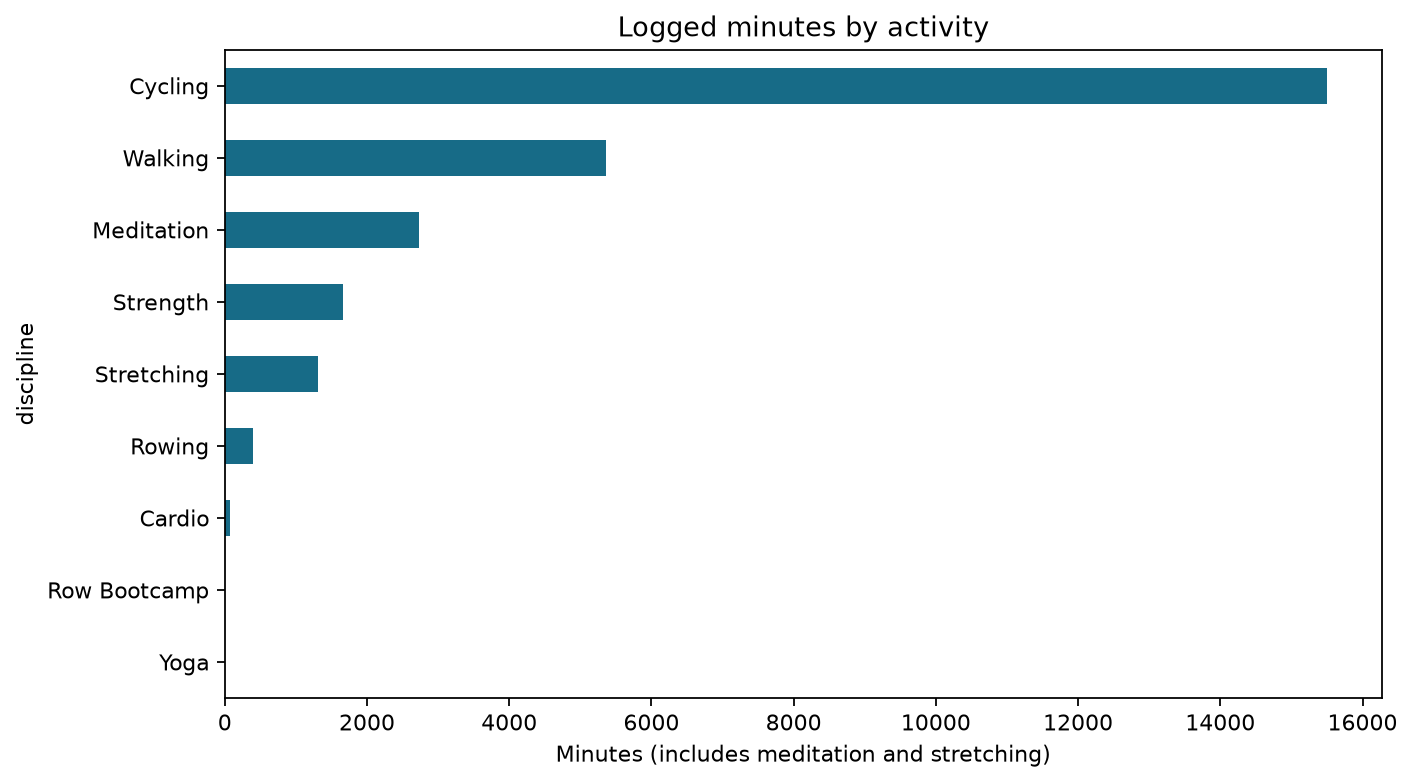

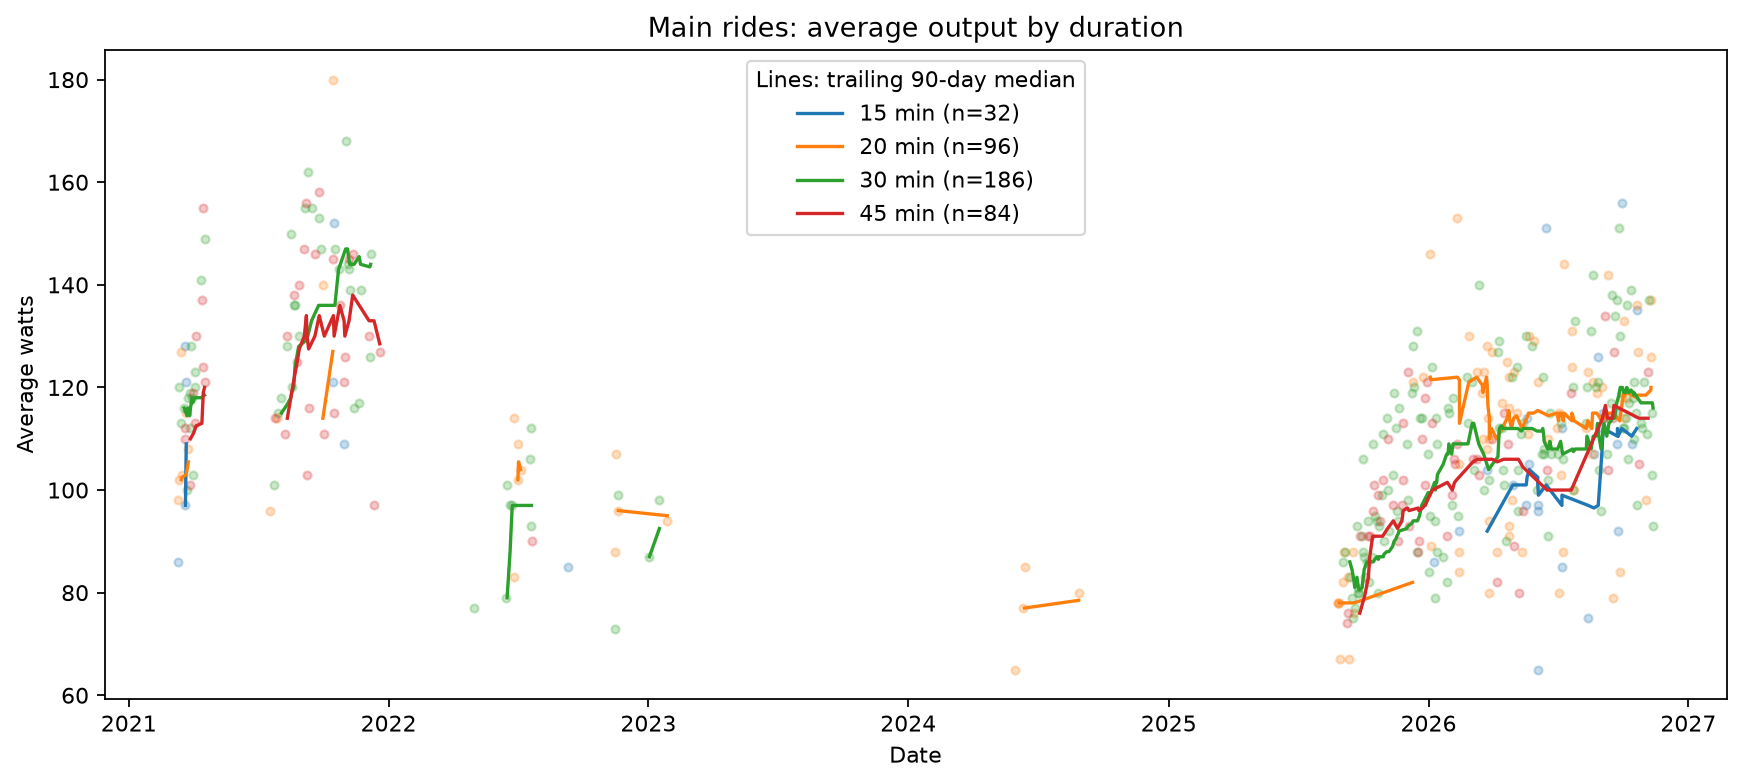

,minutes,type,count,mean,median,std
12,30.0,Music,101,120.653465,117.0,17.659805
11,30.0,Low Impact,55,95.600000,95.0,13.215591
19,45.0,Music,45,120.577778,118.0,18.731948
7,20.0,Music,41,118.707317,120.0,13.581686
6,20.0,Low Impact,31,92.193548,88.0,14.496941
18,45.0,Low Impact,28,100.250000,98.0,11.843501
24,60.0,Music,20,116.150000,114.0,15.601198
16,30.0,Theme,19,113.736842,114.0,15.263763
0,15.0,Low Impact,16,101.687500,101.0,21.856254
1,15.0,Music,12,117.916667,113.5,19.883563


In [3]:
main = descriptive(df, OUT)
print(f"Main rides: {len(main)}")
for name in ["01_consistency.png", "02_activity_mix.png", "03_cycling_performance.png"]:
    display(Image(filename=str(OUT / name)))
display(pd.read_csv(OUT / "comparable_ride_groups.csv").sort_values("count", ascending=False).head(15))

## 3. Construct past-only features
Prior 7/28-day totals and prior 28-day watts exclude the entire current day. Current-ride output, cadence, resistance, calories, distance, and heart rate are excluded from prediction. Recent logged minutes include all disciplines and should not be called physiological load.

In [4]:
rides = make_features(df, main)
display(rides[["date", "minutes", "watts", "prior_7d_minutes", "prior_28d_watts"]].head(12))

,date,minutes,watts,prior_7d_minutes,prior_28d_watts
0,2021-03-11 16:49:00,20.0,98.0,0.0,NaN
1,2021-03-11 17:13:00,15.0,86.0,0.0,NaN
2,2021-03-12 06:17:00,20.0,102.0,35.0,92.000000
3,2021-03-12 16:54:00,30.0,120.0,35.0,92.000000
4,2021-03-14 16:17:00,30.0,113.0,85.0,101.500000
6,2021-03-15 17:21:00,20.0,127.0,120.0,103.800000
8,2021-03-16 17:27:00,20.0,103.0,145.0,107.666667
9,2021-03-19 17:36:00,30.0,116.0,130.0,107.000000
10,2021-03-20 11:42:00,45.0,110.0,110.0,108.125000
11,2021-03-20 12:31:00,15.0,97.0,110.0,108.125000


## 4. Evaluate predictions on later workouts
Use the latest 20% of distinct ride days as a holdout. Compare a training-mean baseline, ridge regression, and a fixed random forest. No random train/test split or tuning on the holdout. Predictions are sequential: a later holdout day can use outcomes from completed earlier days.

Completed


,model,MAE_watts,RMSE_watts,R2
0,Training mean baseline,13.209240,16.847491,-0.203389
1,Ridge regression,11.818745,14.679599,0.086383
2,Random forest,15.061147,18.710943,-0.484318


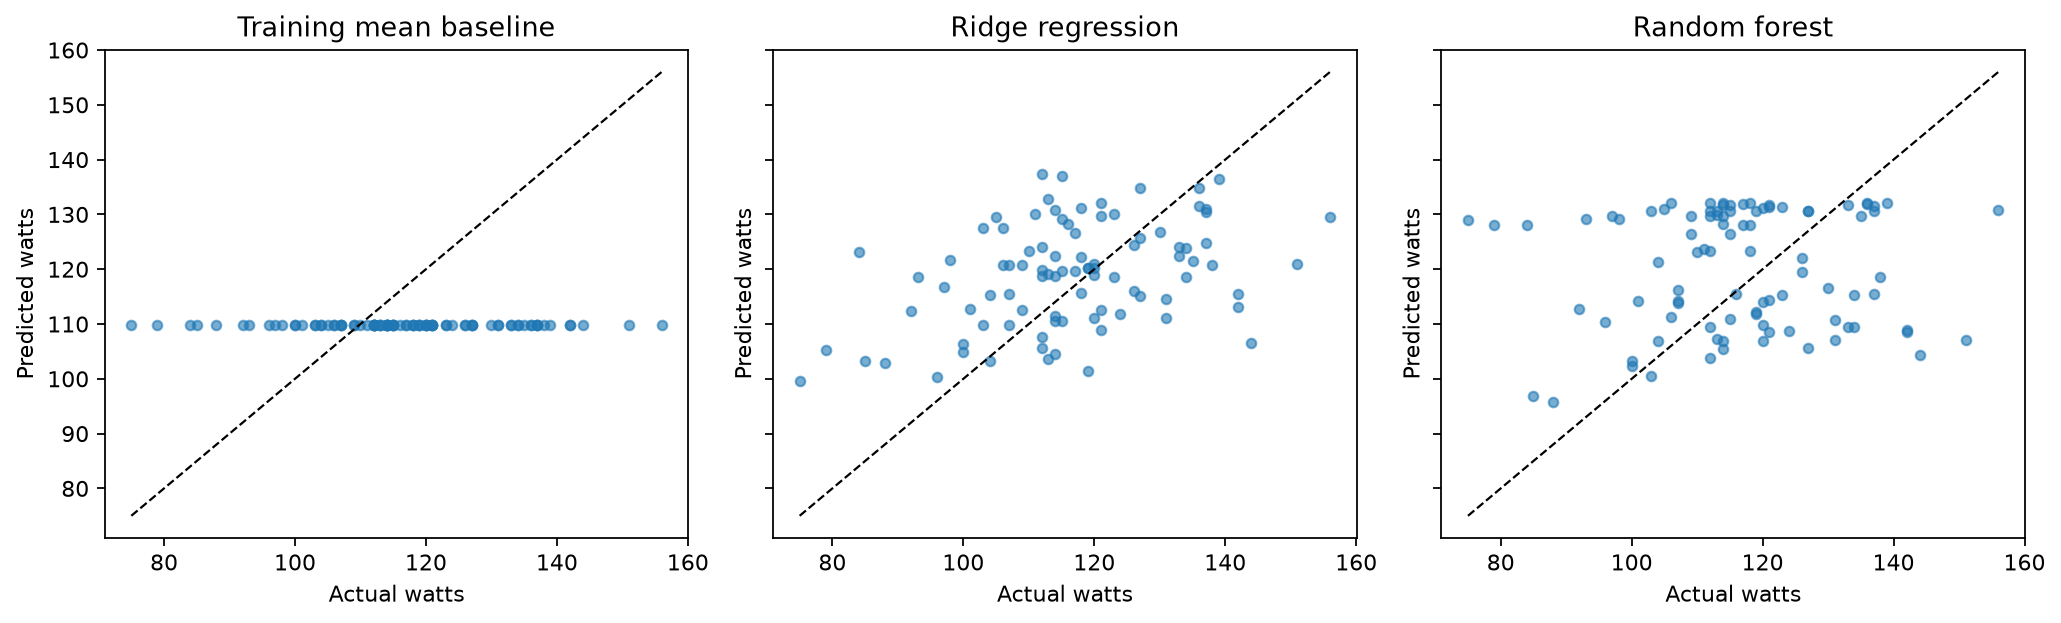

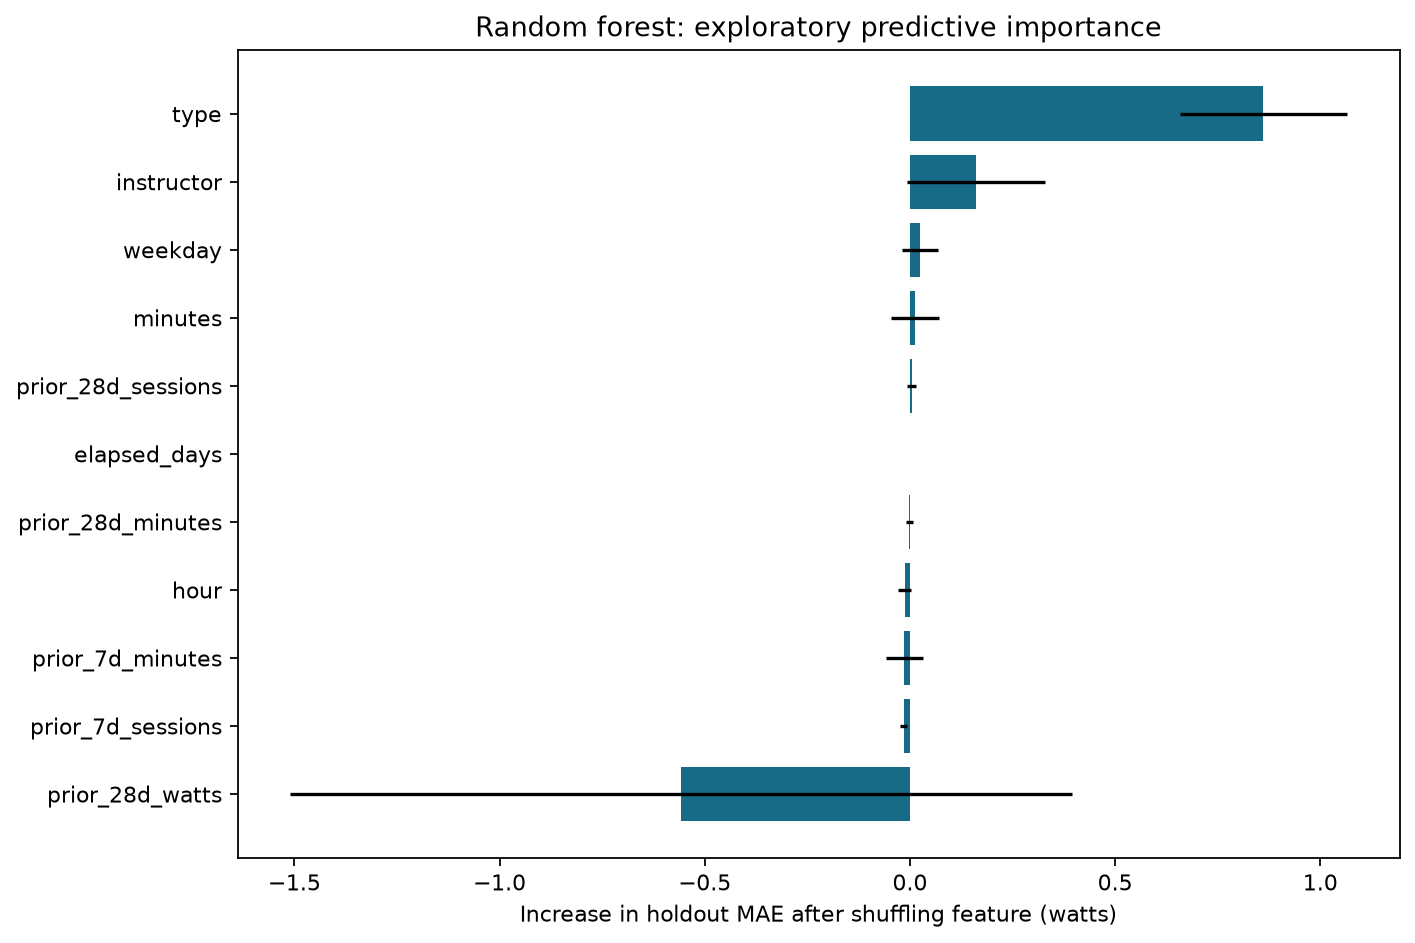

In [5]:
result = model_analysis(rides, OUT)
print(result["status"])
if result["status"] == "Completed":
    display(pd.read_csv(OUT / "model_scores.csv"))
    display(Image(filename=str(OUT / "04_prediction_comparison.png")))
    display(Image(filename=str(OUT / "05_predictive_importance.png")))

## 5. Discuss the evidence
1. Which activity patterns changed, including long gaps?
2. Do watts change within similar-duration rides? Could class mix explain the difference?
3. Does either model beat the baseline, and by how many watts?
4. Why might a more complex model perform worse?
5. What additional information would help (effort ratings, equipment history, sleep)?

Do not infer causation, weight-loss effects, or physiological fitness gains from these records alone. Feature importance describes predictive associations, not training prescriptions. A single-person dataset and one chronological holdout limit generalization.